<a href="https://colab.research.google.com/github/suryansh24-coder/Machine-Learning-Journey/blob/main/ROC_AUC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import plotly.graph_objects as go
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score,roc_curve
from sklearn.preprocessing import StandardScaler

In [3]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    random_state=42
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (800, 10)
X_test shape: (200, 10)


In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
lr_scores = lr_model.predict_proba(X_test_scaled)[:,1]

In [7]:
svm_model = SVC(probability=True)
svm_model.fit(X_train_scaled, y_train)
svm_scores = svm_model.predict_proba(X_test_scaled)[:,1]

In [8]:
lr_fpr , lr_tpr , lr_thresholds = roc_curve(y_test , lr_scores)
svm_fpr , svm_tpr , svm_thresholds = roc_curve(y_test , svm_scores)

In [9]:
lr_auc = roc_auc_score(y_test , lr_scores)

In [10]:
svm_fpr ,svm_tpr , svm_thresholds = roc_curve(y_test , svm_scores)
svm_auc = roc_auc_score(y_test , svm_scores)

In [11]:
trace0 = go.Scatter(
    x = lr_fpr,
    y = lr_tpr,
    name = 'Logistic Regression',
    mode = 'lines',
    line = dict(color = 'blue')
)

trace1 = go.Scatter(
    x = svm_fpr,
    y = svm_tpr,
    name = 'Support Vector Machine',
    mode = 'lines',
    line = dict(color = 'red')
)

trace2 = go.Scatter(
    x = [0,1],
    y = [0,1],
    name = 'Random Classifier',
    mode = 'lines',
    line = dict(color = 'black', dash = 'dash')
)

layout = go.Layout(
    title = 'ROC Curve',
    xaxis = dict(title = 'False Positive Rate'),
    yaxis = dict(title = 'True Positive Rate'),
    autosize = False,
    width = 800,
    height = 600
)

fig = go.Figure(data = [trace0, trace1, trace2], layout = layout)
fig.show()

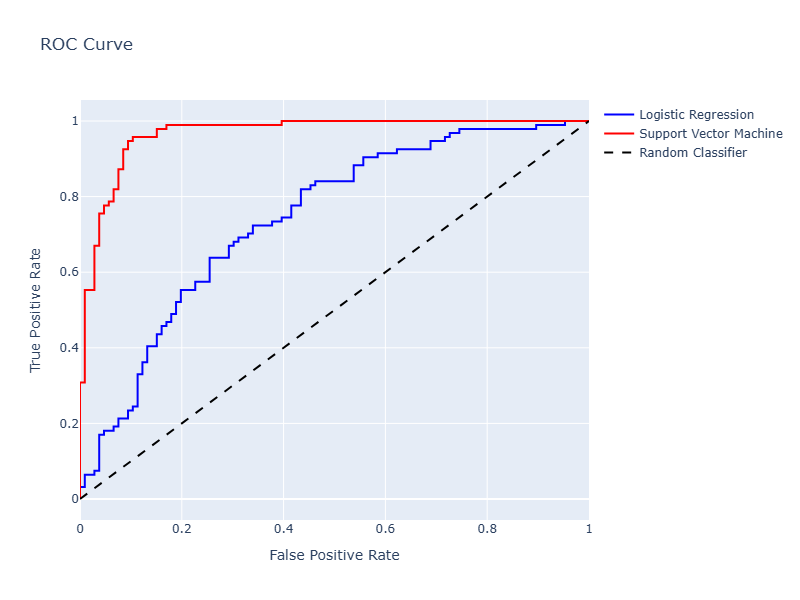